# UTS KLASIFIKASI

## BUSINESS UNDERSTANDING

Proyek klasifikasi tutupan lahan (Land Use Land Cover) wilayah Jawa Timur ini dikembangkan untuk merespons tingginya dinamika alih fungsi lahan akibat urbanisasi dan pertumbuhan ekonomi. Mengingat pemantauan manual di lapangan sangat tidak efisien, sistem ini memanfaatkan citra satelit Sentinel-2 untuk memetakan permukaan bumi secara otomatis, cepat, dan berkala.

Dengan mengekstrak nilai spektral dari Band 4 (Red), Band 8A (Narrow NIR), dan Band 11 (SWIR), model Machine Learning yang dibangun mampu mengatasi kebingungan visual pada citra standar. Sistem dapat membedakan secara presisi objek-objek yang sering kali mengecoh mata manusia, seperti memisahkan hutan daratan dengan hutan mangrove pesisir, atau lahan pertanian produktif dengan area terbangun (build-up area).

Hasil akhir dari prediksi model ini disajikan dalam bentuk dashboard peta interaktif. Melalui platform ini, para pengambil kebijakan dapat langsung memfilter dan memantau distribusi lahan secara real-time demi mendukung perencanaan tata ruang serta pelestarian lingkungan yang lebih akurat.


## DATA UNDERSTANDING

Tahap Data Understanding bertujuan untuk memahami karakteristik, distribusi, dan rincian data spektral yang diekstrak, serta mengidentifikasi potensi masalah pada data sebelum masuk ke tahap pemodelan.

Proses Akuisisi dan Penyiapan Data...
Data lokal belum lengkap. Menginisialisasi Google Earth Engine...
Earth Engine berhasil terhubung.

Membaca file poligon acuan 'UTS_data.geojson'...
Berhasil memuat 251 poligon sampel ke server.

File 'Sentinel2_Area.tif' tidak ditemukan. Memulai proses unduhan citra untuk inferensi spasial...
Mengeksekusi proses pengunduhan citra skala spasial 100 meter...


  0%|          |0/175 tiles [00:00<?]

C:\Users\mappattiro\kal\kal\Lib\site-packages\geedim\image.py:254: RuntimeWarning: Couldn't find STAC entry for: 'None'.
  return STACClient().get(self.id)


Unduhan selesai. File raster spasial berhasil disimpan ke 'Sentinel2_Area.tif'.

Analisis Eksplorasi Data (Data Understanding)...
Struktur Dataset:
Total baris data (piksel) : 423909
Total kolom              : 6 (1 label 'Class', 5 fitur spektral)

Distribusi Kelas:
 - Perairan       : 379374 piksel
 - Hutan          : 38532 piksel
 - Hutan Mangrove : 4176 piksel
 - Sawah          : 1340 piksel
 - Bangunan       : 487 piksel

Samples Data Teratas:


,Class,Band_2,Band_3,Band_4,B8A,Band_11
0,Hutan Mangrove,550.090909,790.444444,636.200000,3210.666667,1517.625000
1,Hutan Mangrove,539.357143,801.000000,595.000000,3261.250000,1650.583333
2,Hutan Mangrove,412.571429,732.315789,484.250000,3708.833333,1839.000000
3,Hutan Mangrove,542.000000,800.214286,596.500000,3023.000000,1580.200000
4,Hutan Mangrove,536.250000,823.384314,607.307692,3366.333333,1711.666667


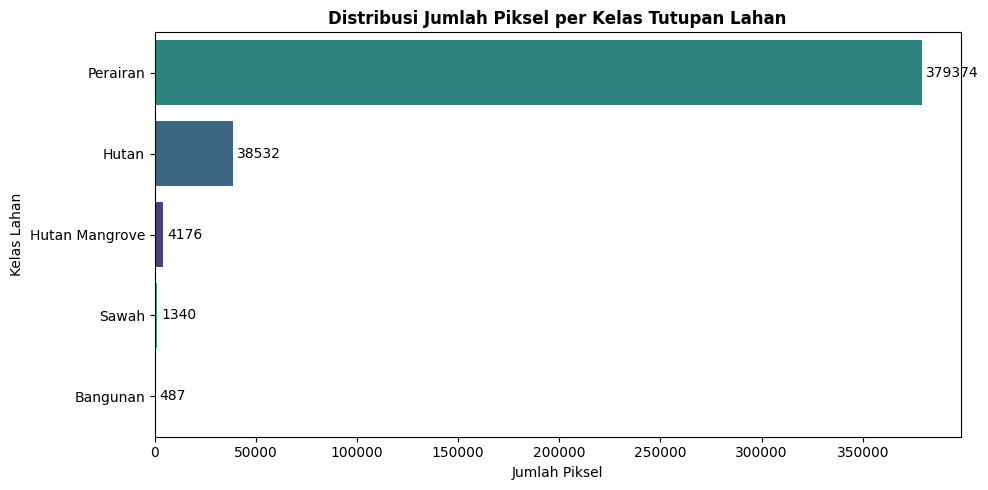

In [12]:
import os
import json
import pandas as pd
import urllib.request
import ee
import geemap
import matplotlib.pyplot as plt
import seaborn as sns

file_csv = 'dataset_training.csv'
file_tif = 'Sentinel2_Area.tif'

print("Proses Akuisisi dan Penyiapan Data...")

if os.path.exists(file_csv) and os.path.exists(file_tif):
    print(f"File '{file_csv}' dan '{file_tif}' ditemukan. Menggunakan data lokal...\n")
else:
    print("Data lokal belum lengkap. Menginisialisasi Google Earth Engine...")
    try:
        ee.Initialize()
    except Exception as e:
        ee.Authenticate()
        ee.Initialize()
    print("Earth Engine berhasil terhubung.\n")

    print("Membaca file poligon acuan 'UTS_data.geojson'...")
    with open('UTS_data.geojson', 'r') as f:
        geojson_data = json.load(f)
        
    pemetaan_kelas = {
        'Hutan Mangrove\n': 'Hutan Mangrove',
        'Hutan biasa (Forest)': 'Hutan',
        'Lautan, danau, perairan ( water body)': 'Perairan',
        'Lahan pertanian ( farm land) ': 'Sawah',
        'Bagunan ( build up) ': 'Bangunan'
    }
    
    fitur_valid = []
    for feature in geojson_data['features']:
        if 'Class' in feature['properties']:
            nama_asli = feature['properties']['Class']
            if nama_asli in pemetaan_kelas:
                feature['properties']['Class'] = pemetaan_kelas[nama_asli]
                fitur_valid.append(feature)
            
    fc = ee.FeatureCollection(fitur_valid)
    print(f"Berhasil memuat {fc.size().getInfo()} poligon sampel ke server.\n")

    # Ekstraksi Data Tabular CSV
    if not os.path.exists(file_csv):
        print(f"Mengekstrak data latih ke '{file_csv}'...")
        # Menggunakan 'B8a' huruf kecil agar sesuai standar GEE
        s2 = ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED") \
            .filterBounds(fc.geometry()) \
            .filterDate('2025-01-01', '2026-09-30') \
            .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 50)) \
            .median() \
            .select(['B2', 'B3', 'B4', 'B8a', 'B11']) 

        sampled = s2.sampleRegions(
            collection=fc, properties=['Class'], scale=10, tileScale=16, geometries=False
        )

        url = sampled.getDownloadURL(filetype='csv', selectors=['Class', 'B2', 'B3', 'B4', 'B8A', 'B11'])
        urllib.request.urlretrieve(url, file_csv)
        
        # Penyelarasan nama kolom input dan output
        df_temp = pd.read_csv(file_csv).dropna()
        df_temp = df_temp.rename(columns={
            'B2': 'Band_2', 
            'B3': 'Band_3', 
            'B4': 'Band_4', 
            'B8a': 'Band_8A', 
            'B11': 'Band_11'
        })
        df_temp.to_csv(file_csv, index=False)
        print(f"Data latih CSV berhasil disimpan.\n")

    # Ekstraksi Citra Raster TIF (Perbaikan Indentasi Struktural)
    if not os.path.exists(file_tif):
        print(f"File '{file_tif}' tidak ditemukan. Memulai proses unduhan citra untuk inferensi spasial...")
        
        roi = fc.geometry().bounds()
        s2_tif = ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED") \
            .filterBounds(roi) \
            .filterDate('2025-01-01', '2026-09-30') \
            .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10)) \
            .median() \
            .select(['B2', 'B3', 'B4', 'B8A', 'B11'])
            
        print("Mengeksekusi proses pengunduhan citra skala spasial 100 meter...")
        geemap.download_ee_image(
            s2_tif, 
            filename=file_tif, 
            scale=100,  
            region=roi,
            crs='EPSG:4326'
        )
        print(f"Unduhan selesai. File raster spasial berhasil disimpan ke '{file_tif}'.\n")


print("Analisis Eksplorasi Data (Data Understanding)...")
df = pd.read_csv(file_csv)

baris, kolom = df.shape
print("Struktur Dataset:")
print(f"Total baris data (piksel) : {baris}")
print(f"Total kolom              : {kolom} (1 label 'Class', {kolom-1} fitur spektral)\n")

print("Distribusi Kelas:")
distribusi = df['Class'].value_counts()
for kelas, jumlah in distribusi.items():
    print(f" - {kelas:<15}: {jumlah} piksel")

print("\nSamples Data Teratas:")
display(df.head())

# Visualisasi Distribusi Data
plt.figure(figsize=(10, 5))
grafik = sns.countplot(
    data=df, 
    y='Class', 
    order=distribusi.index, 
    palette='viridis',
    hue='Class',
    legend=False
)
plt.title('Distribusi Jumlah Piksel per Kelas Tutupan Lahan', fontsize=12, fontweight='bold')
plt.xlabel('Jumlah Piksel')
plt.ylabel('Kelas Lahan')

max_width = distribusi.max()
offset = max_width * 0.005 

for p in grafik.patches:
    width = p.get_width()
    grafik.annotate(f'{int(width)}', 
                    (width + offset, p.get_y() + p.get_height() / 2.), 
                    ha='left', va='center', fontsize=10)

plt.tight_layout()
plt.show()



### Sumber Data dan Skenario Ekstraksi

Data tabular diekstrak berdasarkan 251 area Region of Interest (ROI) berformat GeoJSON yang tersebar di wilayah Jawa Timur. Nilai piksel disedot menggunakan Google Earth Engine API (cloud-based) dengan parameter ekstraksi sebagai berikut:

- Koleksi Citra: Sentinel-2 Level-2A (Bottom of Atmosphere).
- Rentang Waktu: 1 Januari 2025 hingga 30 September 2026.
- Toleransi Awan: Maksimum 50%. Reduksi awan dilakukan secara otomatis menggunakan metode Median Reducer (mengambil nilai spektral tengah yang paling bersih dari rentang waktu tersebut).
- Metode Unduh: Data diekstrak melalui URL download menjadi file dataset_training.csv untuk menghindari limitasi memori 5.000 elemen pada server Google.


### Karakteristik Fitur (Spektral Band)

Dataset ini menggunakan 5 variabel (features) independen berupa pantulan cahaya (reflektansi) dari saluran satelit Sentinel-2. Pemilihan band ini bertujuan untuk memisahkan 5 kelas lahan secara optimal:


| Nama Fitur | Fungsi Klasifikasi |
|---|---|
| Band 2 (Blue) & Band 3 (Green) | Sangat sensitif terhadap pantulan air. Kehadiran dua band ini krusial untuk membedakan kelas Perairan dengan objek gelap lain seperti bayangan atau aspal. |
| Band 4 (Red) | Menyerap klorofil tanaman secara kuat. Sangat esensial untuk mendeteksi kerapatan daun dan memisahkan vegetasi dari non-vegetasi. |
| Band 8a (Narrow NIR) | Memiliki rentang gelombang inframerah dekat yang sempit dan presisi. Mampu menembus gangguan aerosol atmosfer lebih baik dari B8 biasa, sehingga sangat akurat untuk membedakan detail vegetasi spesifik (Hutan Mangrove vs Hutan biasa). |
| Band 11 (SWIR) | Sangat sensitif terhadap kelembapan tanah, kandungan air pada kanopi, dan material beton. Menjadi fitur penegas utama untuk mengklasifikasikan area Bangunan dan Sawah kering. |


Struktur Dataset:
Total baris data (piksel) : 423909
Total kolom              : 6 (1 label 'Class', 5 fitur spektral)

Distribusi Kelas:
 - Perairan       : 379374 piksel
 - Hutan          : 38532 piksel
 - Hutan Mangrove : 4176 piksel
 - Sawah          : 1340 piksel
 - Bangunan       : 487 piksel

Samples Data Teratas:


,Class,Band_2,Band_3,Band_4,B8A,Band_11
0,Hutan Mangrove,550.090909,790.444444,636.200000,3210.666667,1517.625000
1,Hutan Mangrove,539.357143,801.000000,595.000000,3261.250000,1650.583333
2,Hutan Mangrove,412.571429,732.315789,484.250000,3708.833333,1839.000000
3,Hutan Mangrove,542.000000,800.214286,596.500000,3023.000000,1580.200000
4,Hutan Mangrove,536.250000,823.384314,607.307692,3366.333333,1711.666667


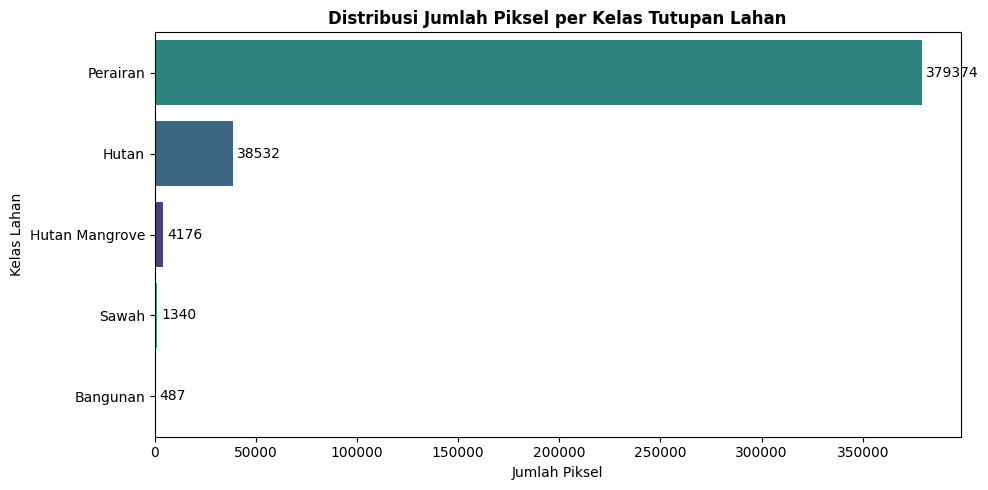

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('dataset_training.csv')

# Informasi Dimensi Dataset
baris, kolom = df.shape
print("Struktur Dataset:")
print(f"Total baris data (piksel) : {baris}")
print(f"Total kolom              : {kolom} (1 label 'Class', {kolom-1} fitur spektral)\n")

# Informasi Distribusi Kelas
print("Distribusi Kelas:")
distribusi = df['Class'].value_counts()
for kelas, jumlah in distribusi.items():
    print(f" - {kelas:<15}: {jumlah} piksel")

print("\nSamples Data Teratas:")
display(df.head())

# Visualisasi Distribusi Kelas
plt.figure(figsize=(10, 5))
grafik = sns.countplot(
    data=df, 
    y='Class', 
    order=distribusi.index, 
    palette='viridis',
    hue='Class',
    legend=False
)
plt.title('Distribusi Jumlah Piksel per Kelas Tutupan Lahan', fontsize=12, fontweight='bold')
plt.xlabel('Jumlah Piksel')
plt.ylabel('Kelas Lahan')

# Menampilkan label angka secara dinamis di ujung bar grafik
max_width = distribusi.max()
offset = max_width * 0.005 

for p in grafik.patches:
    width = p.get_width()
    grafik.annotate(f'{int(width)}', 
                    (width + offset, p.get_y() + p.get_height() / 2.), 
                    ha='left', va='center', fontsize=10)

plt.tight_layout()
plt.show()



### Temuan Kritis (Data Issues)

Berdasarkan hasil analisis, dataset ini mengalami masalah Extreme Class Imbalance (ketidakseimbangan kelas yang ekstrem). Kelas Perairan mendominasi sekitar 89,5% dari keseluruhan data piksel, sementara kelas Bangunan hanya mencakup sebagian kecil dari total dataset.
Kondisi data yang timpang ini berisiko tinggi membuat model mengalami bias mayoritas, di mana algoritma akan cenderung salah memprediksi objek non-perairan sebagai Perairan demi mencapai akurasi semu yang tinggi. Oleh karena itu, tahap Data Preparation berikutnya wajib menerapkan strategi penyeimbangan data (data balancing), baik melalui metode undersampling pada kelas mayoritas maupun oversampling (seperti SMOTE) pada kelas minoritas sebelum data masuk ke proses pelatihan model.


### Pengecekan Missing Values

Sebelum melangkah ke tahap selanjutnya, perlu dipastikan bahwa seluruh piksel memiliki nilai spektral yang lengkap. Hal ini dilakukan untuk mengidentifikasi adanya data kosong akibat kendala teknis saat perekaman objek, seperti tutupan awan pekat, bayangan awan, atau gangguan pada sensor satelit.

In [21]:
# Memeriksa jumlah data kosong (null/NaN) di setiap kolom
missing_data = df.isnull().sum()
total_missing = missing_data.sum()

print("Jumlah Nilai Kosong per Kolom:")
print(missing_data)
print(f"\nTotal nilai kosong: {total_missing}")

if total_missing == 0:
    print("Dataset bersih dari nilai kosong.")
else:
    print(f"Peringatan: Ditemukan {total_missing} nilai kosong yang perlu ditangani.")


Jumlah Nilai Kosong per Kolom:
Class      0
Band_2     0
Band_3     0
Band_4     0
B8A        0
Band_11    0
dtype: int64

Total nilai kosong: 0
Dataset bersih dari nilai kosong.


## Data Preparation
Tahap ini bertujuan untuk menyiapkan dataset agar optimal sebelum masuk ke proses pemodelan, dengan fokus utama menyelesaikan masalah ketidakseimbangan kelas (class imbalance) yang sangat ekstrem melalui pendekatan hibrida (hybrid balancing).

| Masalah Data | Dampak Jika Dibiarkan | Solusi yang Diterapkan |
|---|---|---|
| **Extreme Class Imbalance** <br><br> Kelas Perairan mendominasi ~89,5% (379.374 piksel), sedangkan kelas Bangunan hanya ~0,1% (487 piksel). | **Bias Mayoritas & Paradoks Akurasi** <br><br> Model cenderung menebak semua objek sebagai Perairan untuk cari aman. Kelas minoritas (Bangunan & Sawah) akan dianggap sebagai noise dan gagal terdeteksi. | **1. Stratified Train-Test Split (80:20)** <br> Memisahkan data latih dan uji dengan mempertahankan proporsi kelas asli. Proses penyeimbangan hanya dilakukan pada data latih agar data uji tetap objektif. <br><br> **2. Hybrid Balancing (Threshold 5.000 Piksel)** <br> * Undersampling: Memangkas data Perairan dan Hutan secara acak menjadi 5.000 piksel untuk menghemat komputasi. <br> * SMOTE: Membuat piksel sintetis baru lewat interpolasi untuk mendongkrak data Bangunan, Sawah, dan Mangrove menjadi 5.000 piksel. |


Distribusi Data Latih (Sebelum Balancing):
Class
Perairan          303499
Hutan              30825
Hutan Mangrove      3341
Sawah               1072
Bangunan             390
Name: count, dtype: int64

Distribusi Data Latih (Setelah Balancing):
Class
Bangunan          5000
Hutan             5000
Hutan Mangrove    5000
Perairan          5000
Sawah             5000
Name: count, dtype: int64


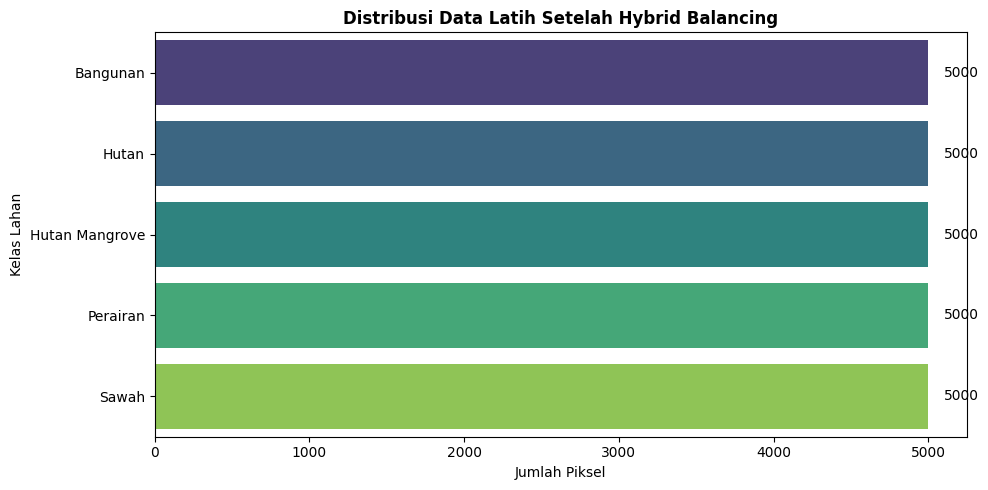

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

df = pd.read_csv('dataset_training.csv').dropna()

# Pemisahan fitur spektral dan variabel target
X = df.drop(columns=['Class'])
y = df['Class']

# Stratified Train-Test Split (80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Distribusi Data Latih (Sebelum Balancing):")
print(y_train.value_counts())

# Penerapan Hybrid Balancing
target_threshold = 5000

# Tahap 1: Undersampling untuk kelas mayoritas
under_strategy = {'Perairan': target_threshold, 'Hutan': target_threshold}
under_sampler = RandomUnderSampler(sampling_strategy=under_strategy, random_state=42)
X_train_under, y_train_under = under_sampler.fit_resample(X_train, y_train)

# Tahap 2: SMOTE untuk kelas minoritas
over_strategy = {'Hutan Mangrove': target_threshold, 'Sawah': target_threshold, 'Bangunan': target_threshold}
over_sampler = SMOTE(sampling_strategy=over_strategy, random_state=42)
X_train_bal, y_train_bal = over_sampler.fit_resample(X_train_under, y_train_under)

print("\nDistribusi Data Latih (Setelah Balancing):")
print(y_train_bal.value_counts())

# Visualisasi Hasil Balancing
plt.figure(figsize=(10, 5))
grafik = sns.countplot(
    y=y_train_bal, 
    palette='viridis', 
    order=y_train_bal.value_counts().index,
    hue=y_train_bal,
    legend=False
)
plt.title('Distribusi Data Latih Setelah Hybrid Balancing', fontsize=12, fontweight='bold')
plt.xlabel('Jumlah Piksel')
plt.ylabel('Kelas Lahan')

# Menampilkan label angka statis secara rapi di ujung bar grafik
for p in grafik.patches:
    width = p.get_width()
    grafik.annotate(f'{int(width)}', 
                    (width + 100, p.get_y() + p.get_height() / 2.), 
                    ha='left', va='center', fontsize=10)

plt.tight_layout()
plt.show()



## Modeling

Tahap ini merupakan inti dari seluruh proses pengembangan, di mana algoritma komputer dilatih menggunakan data spektral yang telah disiapkan agar mampu mengenali karakteristik unik permukaan bumi dan melakukan klasifikasi tutupan lahan secara otomatis.

### Konsep Alur Kerja Pemodelan

Proses pemodelan dibagi menjadi dua fase utama untuk memastikan model yang dihasilkan tidak hanya pintar di data latihan, melainkan juga andal saat diuji dengan data baru:
- Fase Pelatihan (Training): Algoritma Random Forest Classifier dilatih menggunakan data latih hasil penyeimbangan hibrida (hybrid balancing). Di tahap ini, model mempelajari pola dan karakteristik unik dari nilai pantulan spektral Band 2, Band 3, Band 4, Band 8a, dan Band 11 untuk masing-masing target kelas objek.
- Fase Pengujian (Testing): Model yang telah selesai dilatih kemudian dievaluasi menggunakan data uji. Data uji ini sengaja disembunyikan sejak awal dan belum pernah dilihat oleh model selama masa pelatihan. Langkah ini krusial untuk menguji performa objektif model saat dihadapkan pada skenario data dunia nyata yang sesungguhnya.



### Rincian Data Latih dan Uji

Sebelum proses pelatihan dimulai, penting untuk meninjau kembali rincian dimensi, struktur, serta distribusi kelas dari data latih yang telah diseimbangkan dan data uji yang akan digunakan sebagai validator performa model.

In [24]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Menampilkan informasi dimensi data
print("Dimensi Dataset Pemodelan:")
print(f"Jumlah sampel data latih : {X_train_bal.shape[0]:,}")
print(f"Jumlah sampel data uji   : {X_test.shape[0]:,}")
print(f"Jumlah fitur spektral    : {X_train_bal.shape[1]} (B2, B3, B4, Band_8a, B11)\n")

print("Komposisi Kelas Data Latih:")
print(y_train_bal.value_counts())

print("\nSamples Data Latih:")
display(X_train_bal.head())


Dimensi Dataset Pemodelan:
Jumlah sampel data latih : 25,000
Jumlah sampel data uji   : 84,782
Jumlah fitur spektral    : 5 (B2, B3, B4, Band_8a, B11)

Komposisi Kelas Data Latih:
Class
Bangunan          5000
Hutan             5000
Hutan Mangrove    5000
Perairan          5000
Sawah             5000
Name: count, dtype: int64

Samples Data Latih:


,Band_2,Band_3,Band_4,B8A,Band_11
0,1279.344156,1440.111111,1638.200000,2329.363636,3250.500000
1,736.666667,932.466667,1378.687500,2361.566667,3170.895833
2,1378.250000,1570.250000,2143.750000,2856.285714,3801.000000
3,860.200000,1051.894737,1375.000000,2205.333333,2847.200000
4,738.153846,989.647059,1440.133333,2391.200000,3410.666667



### Proses Pelatihan Model (Training)

Pada tahap ini, algoritma Random Forest diinisialisasi untuk mempelajari hubungan antara karakteristik spektral band satelit dengan kelas tutupan lahan pada data latih. Konfigurasi model menggunakan beberapa parameter kunci dengan alasan teknis berikut:

| Parameter | Nilai / Konfigurasi | Alasan Teknis dan Fungsi |
|---|---|---|
| **n_estimators** | `100` | Membangun 100 pohon keputusan (*decision trees*) secara paralel. Jumlah ini merupakan titik optimal (*sweet spot*) standar untuk menangkap pola spektral yang kompleks tanpa membebani memori komputasi secara berlebihan. |
| **random_state** | `42` | Berfungsi sebagai kunci pengunci keacakan (*seed*). Parameter ini memastikan hasil pengacakan sampel data akan selalu konsisten setiap kali kode dijalankan ulang (*reproducible*). |
| **n_jobs** | `-1` | Memerintahkan komputer untuk menggunakan seluruh inti prosesor (*CPU cores*) secara maksimal untuk mempercepat waktu pelatihan model. |


In [27]:
from sklearn.ensemble import RandomForestClassifier

print("Memulai proses pelatihan model Random Forest...")

# Inisialisasi model dengan konfigurasi parameter optimal
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_bal, y_train_bal)

print("Proses pelatihan selesai. Model berhasil dibangun.")

Memulai proses pelatihan model Random Forest...
Proses pelatihan selesai. Model berhasil dibangun.


### MODEL
Setelah dilakukannya training, didapatkanlah model seperti berikut :

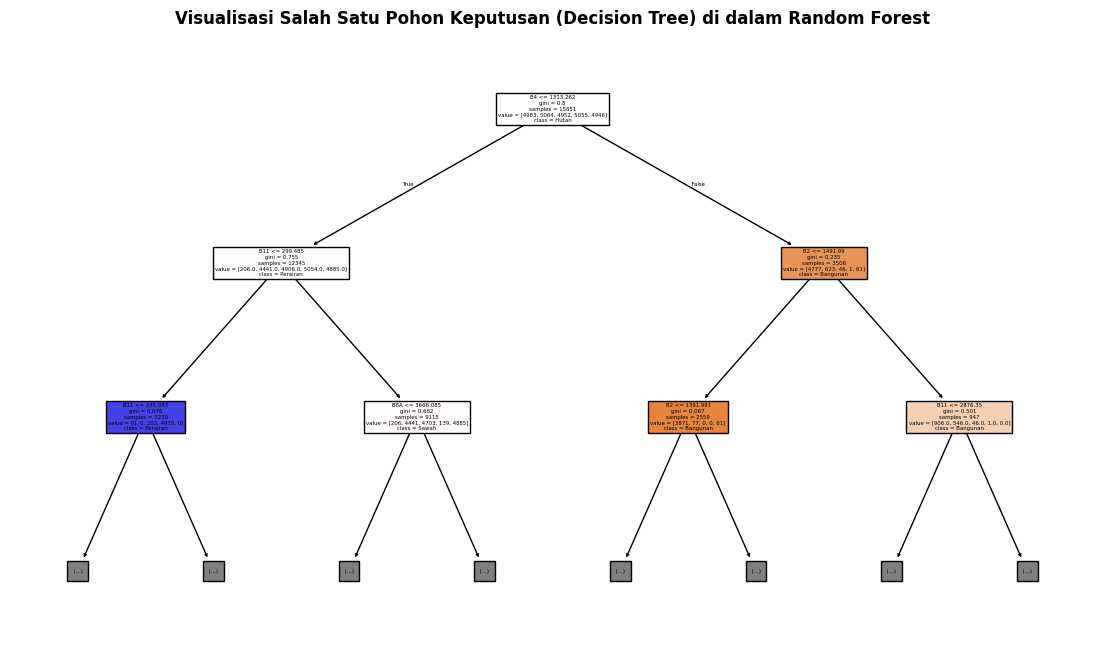

In [29]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Mengambil pohon keputusan pertama dari 100 pohon yang ada
pohon_pertama = rf_model.estimators_[0]

plt.figure(figsize=(14, 8))
plot_tree(pohon_pertama, 
          feature_names=['B2', 'B3', 'B4', 'B8A', 'B11'], 
          class_names=rf_model.classes_, 
          filled=True, 
          max_depth=2) # Dibatasi kedalamannya 3 tingkat agar gambarnya tidak terlalu raksasa

plt.title("Visualisasi Salah Satu Pohon Keputusan (Decision Tree) di dalam Random Forest", fontweight='bold')
plt.show()


### Pengujian dan Evaluasi Model

Setelah proses pelatihan selesai, model diuji menggunakan data uji untuk mengevaluasi performa klasifikasinya secara menyeluruh. Pengujian ini penting untuk melihat kemampuan generalisasi model terhadap data baru yang belum pernah dipelajari sebelumnya.

In [31]:
import pandas as pd
from sklearn.metrics import classification_report, accuracy_score

# Menampilkan rincian jumlah data uji
jumlah_data_uji = X_test.shape[0]
print(f"Total baris data uji (X_test): {jumlah_data_uji:,} piksel")
print("Keterangan: Data uji menggunakan proporsi asli lapangan (tanpa penyeimbangan).\n")

print("Distribusi Kelas Data Uji:")
print(y_test.value_counts())

print("\nMenjalankan prediksi pada data uji...")
y_pred = rf_model.predict(X_test)

# Menghitung evaluasi performa model
akurasi = accuracy_score(y_test, y_pred)
print(f"\nAkurasi Global Model: {akurasi * 100:.2f}%")

print("\nLaporan Klasifikasi Detail:")
print(classification_report(y_test, y_pred))


Total baris data uji (X_test): 84,782 piksel
Keterangan: Data uji menggunakan proporsi asli lapangan (tanpa penyeimbangan).

Distribusi Kelas Data Uji:
Class
Perairan          75875
Hutan              7707
Hutan Mangrove      835
Sawah               268
Bangunan             97
Name: count, dtype: int64

Menjalankan prediksi pada data uji...

Akurasi Global Model: 99.10%

Laporan Klasifikasi Detail:
                precision    recall  f1-score   support

      Bangunan       0.98      1.00      0.99        97
         Hutan       1.00      0.98      0.99      7707
Hutan Mangrove       0.54      0.97      0.69       835
      Perairan       1.00      0.99      1.00     75875
         Sawah       0.92      0.99      0.95       268

      accuracy                           0.99     84782
     macro avg       0.89      0.99      0.92     84782
  weighted avg       0.99      0.99      0.99     84782



## DEPLOYMENT

Pertama, kita buat file .pkl untuk digunakan ke streamlit

In [32]:
import joblib
joblib.dump(rf_model, 'model_rf.pkl')
print("File model_rf.pkl berhasil disimpan!")

File model_rf.pkl berhasil disimpan!


In [15]:
import os
import rasterio
import numpy as np
import joblib

input_tif = 'Sentinel2_Area.tif'
output_tif = 'Hasil_Klasifikasi_LULC.tif'
file_model = 'model_rf.pkl'

if os.path.exists(output_tif):
    print(f"File output '{output_tif}' sudah tersedia. Proses inferensi raster dilewati.")
else:
    print(f"Memuat model Random Forest dari '{file_model}'...")
    rf_model = joblib.load(file_model) 

    print("Membuka citra satelit input...")
    with rasterio.open(input_tif) as src:
        meta = src.meta
        # Membaca 5 Band (B2, B3, B4, Band_8a, B11) secara berurutan sesuai urutan fitur data latih
        img_data = src.read([1, 2, 3, 4, 5]) 
        print(f"Dimensi citra input: {img_data.shape} (Band, Baris, Kolom)")

    # Transformasi matriks 3D menjadi format tabel tabular (2D) untuk input model
    n_bands, baris, kolom = img_data.shape
    img_flatten = img_data.reshape(n_bands, -1).T 

    # Masking piksel background bernilai 0 di luar area kajian
    mask = (img_flatten[:, 0] > 0)
    data_valid = img_flatten[mask]

    print(f"Melakukan klasifikasi pada {data_valid.shape[0]:,} piksel data valid...")
    prediksi_valid = rf_model.predict(data_valid)

    print("Proses klasifikasi selesai. Melakukan pemetaan ulang nilai spektral...")

    # Konversi label kategori string menjadi nilai integer biner untuk format raster GeoTIFF
    kamus_warna = {
        'Perairan': 1,
        'Hutan': 2,
        'Hutan Mangrove': 3,
        'Sawah': 4,
        'Bangunan': 5
    }
    prediksi_angka = np.vectorize(kamus_warna.get)(prediksi_valid)

    # Rekonstruksi bentuk data kembali ke dimensi spasial asli (Baris x Kolom)
    peta_hasil = np.zeros(baris * kolom, dtype=np.uint8)
    peta_hasil[mask] = prediksi_angka
    peta_hasil_2d = peta_hasil.reshape(baris, kolom)

    # Pembaruan metadata file output (1 Band, Format UInt8, NoData = 0)
    meta.update(count=1, dtype=rasterio.uint8, nodata=0) 

    print("Menulis file output raster...")
    with rasterio.open(output_tif, 'w', **meta) as dst:
        dst.write(peta_hasil_2d, 1)

    print(f"Proses selesai. File klasifikasi spasial disimpan di: {output_tif}")


Memuat model Random Forest dari 'model_rf.pkl'...
Membuka citra satelit input...
Dimensi citra input: (5, 2055, 3336) (Band, Baris, Kolom)
Melakukan klasifikasi pada 6,855,477 piksel data valid...


C:\Users\mappattiro\kal\kal\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


Proses klasifikasi selesai. Melakukan pemetaan ulang nilai spektral...
Menulis file output raster...
Proses selesai. File klasifikasi spasial disimpan di: Hasil_Klasifikasi_LULC.tif


### HASIL STREAMLIT

Untuk melihat hasil pemetaan, masuk ke link berikut :
https://lulc-jatim-app-uts.streamlit.app/